# Blacksburg Winters, 1893-2026: How Unusual Is Today's Cold?

*CS 5045 sample final project. It shows the scope, structure, and level of explanation expected in
a technical report. Your project does not need to follow this topic or layout; it should be about
this size.*

**Driving question:** How have Blacksburg winters changed since record-keeping began in 1893, and
how do recent winters compare with those of a generation ago?

A common claim in the New River Valley is that winters "aren't what they used to be." The claim is
usually based on memory, which favors the memorable storms and forgets the mild years. Blacksburg
has a daily temperature record that goes back to 1893, so the claim can be tested directly. Two
versions of the question matter here. The *generational* version compares today with the winters
that current residents grew up with. The *long-term* version asks whether today's winters are
unusual at all once the full 130-year record is considered. The two can have different answers.

### Data sources

Daily observations from NOAA's Global Historical Climatology Network (GHCN-Daily), downloaded in
November 2026 from the National Centers for Environmental Information. Blacksburg's record comes
from two stations in sequence:

| File | Station | Period | Location |
|------|---------|--------|----------|
| `blacksburg_town_1893_1952.csv` | `USC00440765`, *Blacksburg, VA* | Jan 1, 1893 to Oct 31, 1952 | 37.250 N, 80.417 W |
| `blacksburg_nws_1952_2026.csv` | `USC00440766`, *Blacksburg National Weather Service Office* | Nov 1, 1952 to Mar 31, 2026 | 37.204 N, 80.414 W |

The earlier station closed the day before the later one opened. The second site is about 5 km south
of the first. Both files came from the NCEI daily summaries service
([first station](https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&dataTypes=TMAX,TMIN,PRCP,SNOW,SNWD&units=standard&format=csv&includeStationName=true&stations=USC00440765&startDate=1893-01-01&endDate=1952-10-31),
[second station](https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&dataTypes=TMAX,TMIN,PRCP,SNOW,SNWD&units=standard&format=csv&includeStationName=true&stations=USC00440766&startDate=1952-11-01&endDate=2026-03-31)),
requested in U.S. units. Both CSV files should sit in the same folder as this notebook.

Each row is one day. The columns used in this analysis are `TMAX` and `TMIN`, the day's high and low
temperature in °F.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

town_raw = pd.read_csv('blacksburg_town_1893_1952.csv')
nws_raw = pd.read_csv('blacksburg_nws_1952_2026.csv')

## 1. Inspecting the two sources

Before the files can be combined, they need to agree on structure, and their problems need to be
known. The first check is size, columns, and date coverage.

In [2]:
for label, frame in [('Town station', town_raw), ('NWS station', nws_raw)]:
    print(label)
    print('  rows, columns:', frame.shape)
    print('  date range:   ', frame['DATE'].min(), 'to', frame['DATE'].max())
    print('  station IDs:  ', frame['STATION'].unique().tolist())
    print()

print('Same columns in both files:', list(town_raw.columns) == list(nws_raw.columns))

Town station
  rows, columns: (21727, 8)
  date range:    1893-01-01 to 1952-10-31
  station IDs:   ['USC00440765']

NWS station
  rows, columns: (26441, 8)
  date range:    1952-11-01 to 2026-03-31
  station IDs:   ['USC00440766']

Same columns in both files: True


The two files have identical columns, each contains a single station, and together they cover
about 48,000 days with no overlap and no gap at the hand-off: the town station's last day is
October 31, 1952 and the NWS station's first day is November 1, 1952. `DATE` is stored as text in
both and will need conversion.

Next, missing values in each file.

In [3]:
missing = pd.DataFrame({
    'town_1893_1952': town_raw.isnull().sum(),
    'nws_1952_2026': nws_raw.isnull().sum(),
})
print(missing)

         town_1893_1952  nws_1952_2026
STATION               0              0
NAME                  0              0
DATE                  0              0
PRCP               3353             20
SNOW               8133            539
SNWD              19520            350
TMAX                169             80
TMIN                161             68


Temperature is nearly complete in both files: fewer than 200 missing highs or lows out of more
than 20,000 days each. Snowfall is a different story. The town station is missing snowfall on more
than 8,000 days and snow depth on almost 20,000. A blank there could mean "no snow" or "not
recorded," and the file cannot distinguish the two.

A day can also be missing entirely, with no row at all. Counting rows per year shows where that
happens.

In [4]:
for label, frame in [('Town station', town_raw), ('NWS station', nws_raw)]:
    rows_per_year = frame['DATE'].str[:4].value_counts().sort_index()
    print(label, '- years with fewer than 365 rows:')
    print(rows_per_year[rows_per_year < 365].to_dict())
    print()

Town station - years with fewer than 365 rows:
{'1893': 364, '1896': 335, '1902': 364, '1910': 334, '1914': 335, '1923': 333, '1952': 305}

NWS station - years with fewer than 365 rows:
{'1952': 61, '1982': 364, '1986': 364, '1989': 334, '1994': 268, '1995': 153, '2002': 334, '2026': 90}



The short first and last years are expected, since each file starts or ends partway through a
year. The rest are real gaps. The town station is missing about a month in 1896, 1910, 1914, and
1923. The NWS station is missing about a month in 1989 and 2002, and most of 1994 and 1995. Single
missing days (1893, 1902, 1982, 1986) are too small to matter. The analysis must not treat a
winter with a missing month as if it were complete.

Last, are the temperatures believable?

In [5]:
temperature_summary = pd.DataFrame({
    'town_TMAX': town_raw['TMAX'].describe(),
    'town_TMIN': town_raw['TMIN'].describe(),
    'nws_TMAX': nws_raw['TMAX'].describe(),
    'nws_TMIN': nws_raw['TMIN'].describe(),
})
print(temperature_summary.round(1))

       town_TMAX  town_TMIN  nws_TMAX  nws_TMIN
count    21558.0    21566.0   26361.0   26373.0
mean        64.4       41.0      63.5      40.5
std         17.3       15.7      17.5      16.2
min          0.0      -27.0     -69.0     -18.0
25%         51.0       29.0      50.0      28.0
50%         67.0       41.0      66.0      41.0
75%         79.0       55.0      79.0      55.0
max        100.0       80.0      99.0      72.0


Two values stand out.

1. The NWS station's lowest daily **high** is -69°F, far below Virginia's all-time record low of
   about -30°F.
2. The town station's warmest daily **low** is 80°F. The NWS station's warmest low in 74 years is
   72°F, which is plausible for a site at about 2,000 feet of elevation. A night that never drops
   below 80°F is not.

The rows behind both:

In [6]:
impossible_high = nws_raw[nws_raw['TMAX'] < -40]
print('NWS station, impossible high:')
print(impossible_high[['DATE', 'TMAX', 'TMIN']])
print()

warm_nights = town_raw[town_raw['TMIN'] >= 77]
print('Town station, lows of 77 F or warmer:')
print(warm_nights[['DATE', 'TMAX', 'TMIN']])

NWS station, impossible high:
            DATE  TMAX  TMIN
2709  1960-04-02 -69.0  44.0

Town station, lows of 77 F or warmer:
             DATE  TMAX  TMIN
15051  1934-07-23  91.0  77.0
17685  1941-10-08  91.0  80.0
17686  1941-10-09  81.0  78.0
20512  1949-07-05  90.0  78.0


The -69°F high on April 2, 1960 sits beside a normal low of 44°F. It is almost certainly a recording
error, possibly a dropped digit or sign, but the true value cannot be recovered, so it will be set
to missing.

The warm nights are less clear-cut. Lows of 77 to 80°F on a few summer and early-autumn days are
suspicious for this elevation but not impossible to the same degree. They fall outside the winter
months, so they cannot affect this analysis, and I left them in place. They are worth noting for
a different reason: they are an early hint that the two stations may not measure temperature in
exactly the same way. Section 6 returns to that question.

## 2. Combining and cleaning

The cleaning decisions, in the order the code applies them:

1. **Stack the two files into one table** and confirm that no date appears twice.
2. **Replace the station ID code with a readable label** (`town` or `nws`) so every row records its
   source. This column is what allows the station change to be checked later. `NAME` repeats the
   same information and is dropped.
3. **Convert `DATE` to a true date** so months and years can be extracted.
4. **Set the impossible -69°F high to missing.** It falls in April and would never reach the winter
   analysis, but a known-bad value should not remain in the cleaned data.
5. **Keep only December, January, and February**, the standard "meteorological winter." Using fixed
   calendar months keeps every winter the same length.
6. **Assign each day to a winter.** December 1952 and February 1953 belong to the same winter but
   different calendar years. Each winter is named for the year of its January, so December days are
   assigned to the following year. "Winter 2026" means December 2025 through February 2026.
7. **Exclude snowfall.** The town station's snowfall record is too incomplete to compare with modern
   records. The analysis uses temperature only.

Missing days are **not** filled with estimates; filling a missing month would mean inventing a month
of weather. Section 3 instead removes winters with too many missing days.

In [7]:
weather = pd.concat([town_raw, nws_raw], ignore_index=True)
print('Dates appearing more than once:', weather['DATE'].duplicated().sum())

weather['station'] = weather['STATION'].map({'USC00440765': 'town', 'USC00440766': 'nws'})
weather = weather.drop(columns=['STATION', 'NAME'])
weather['DATE'] = pd.to_datetime(weather['DATE'])

impossible = weather['TMAX'] < -40
weather.loc[impossible, 'TMAX'] = None

weather['month'] = weather['DATE'].dt.month
winter_days = weather[weather['month'].isin([12, 1, 2])].copy()

winter_days['winter'] = winter_days['DATE'].dt.year
is_december = winter_days['month'] == 12
winter_days.loc[is_december, 'winter'] = winter_days.loc[is_december, 'winter'] + 1

print()
print('Combined raw data:', weather.shape)
print('Winter days only: ', winter_days.shape)
print()
print('Winter days by station:')
print(winter_days['station'].value_counts())
print()
boundary_dates = pd.to_datetime(['1951-12-01', '1952-02-29', '1952-12-01', '1953-02-28'])
print(winter_days[winter_days['DATE'].isin(boundary_dates)][['DATE', 'winter', 'station', 'TMAX', 'TMIN']])

Dates appearing more than once: 0

Combined raw data: (48168, 8)
Winter days only:  (11939, 9)

Winter days by station:
station
nws     6557
town    5382
Name: count, dtype: int64

            DATE  winter station  TMAX  TMIN
21391 1951-12-01    1952    town  62.0  20.0
21481 1952-02-29    1952    town  60.0  38.0
21757 1952-12-01    1953     nws  37.0  10.0
21846 1953-02-28    1953     nws  52.0  30.0


The cleaned table holds about 11,900 winter days, roughly a quarter of the combined file, with a
`station` label on every row and two redundant columns removed. The four sample rows show the winter
labeling at the station change: December 1, 1951 and February 29, 1952 both belong to winter 1952,
the last winter at the town station, while December 1, 1952 opens winter 1953 at the NWS office.

## 3. From days to winters

Each winter is summarized with three measures. An average alone could hide important differences:
two winters with the same average can differ sharply in how often severe cold arrives.

- **Average daily temperature:** the midpoint of each day's high and low, averaged over the winter.
  This matches how the weather service computes a daily mean.
- **Freezing nights:** days with a low of 32°F or below, a measure of ordinary winter cold.
- **Bitter nights:** days with a low of 10°F or below, the severe cold that freezes pipes and makes
  the news.

The **daily temperature range** (high minus low) is also computed. It is not part of the main
question, but Section 6 uses it to check the station change.

In [8]:
winter_days['daily_mean'] = (winter_days['TMAX'] + winter_days['TMIN']) / 2
winter_days['daily_range'] = winter_days['TMAX'] - winter_days['TMIN']
winter_days['freezing_night'] = winter_days['TMIN'] <= 32
winter_days['bitter_night'] = winter_days['TMIN'] <= 10

winters = winter_days.groupby('winter').agg(
    station=('station', 'first'),
    days_recorded=('TMIN', 'count'),
    mean_temp=('daily_mean', 'mean'),
    daily_range=('daily_range', 'mean'),
    freezing_nights=('freezing_night', 'sum'),
    bitter_nights=('bitter_night', 'sum'),
)

print('Winters in the data:', len(winters))
print()
print('Winters with fewer than 81 days of readings (90% of a full winter):')
print(winters[winters['days_recorded'] < 81][['station', 'days_recorded']])

Winters in the data: 133

Winters with fewer than 81 days of readings (90% of a full winter):
       station  days_recorded
winter                       
1893      town             59
1924      town             65
2002       nws             59


Three winters fall short.

- **1893:** the record begins on January 1, 1893, so December 1892 was never observed.
- **1924:** most of December 1923 is missing.
- **2002:** all of December 2001 is missing.

Each is missing between a quarter and a third of its days. Keeping them would bias their averages toward the
months that happened to be recorded, and would undercount their freezing nights, so all three are
removed. Winter 1995 does not appear at all because the 1994-1995 gap left no rows to summarize.

No winter mixes the two stations: the town station ends in October 1952, so winter 1952 is the last
winter recorded there and winter 1953 is the first recorded at the NWS office.

In [9]:
complete_winters = winters[winters['days_recorded'] >= 81].copy()
print('Complete winters kept:', len(complete_winters))
print(complete_winters.groupby('station').size())

Complete winters kept: 130
station
nws     72
town    58
dtype: int64


## 4. One hundred thirty winters

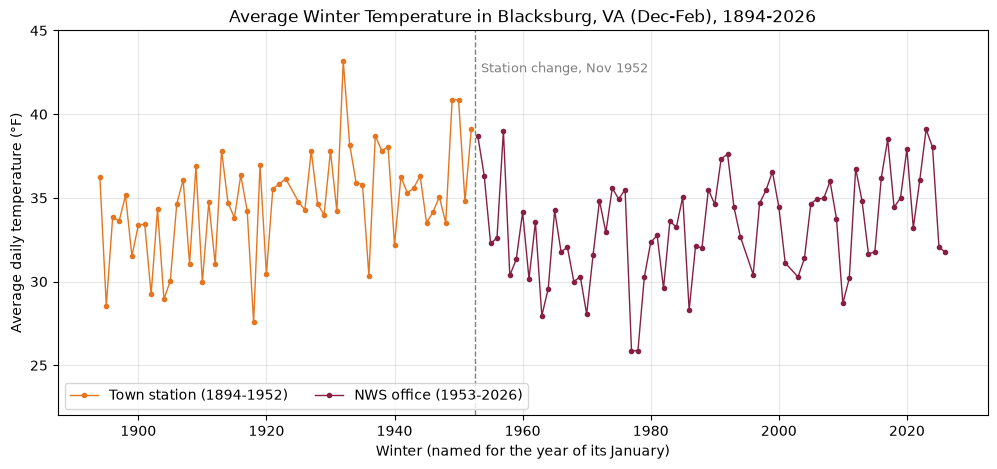

In [10]:
town_winters = complete_winters[complete_winters['station'] == 'town']
nws_winters = complete_winters[complete_winters['station'] == 'nws']

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(town_winters.index, town_winters['mean_temp'], marker='o', markersize=3,
        linewidth=1, color='#E5751F', label='Town station (1894-1952)')
ax.plot(nws_winters.index, nws_winters['mean_temp'], marker='o', markersize=3,
        linewidth=1, color='#861F41', label='NWS office (1953-2026)')
ax.axvline(1952.5, color='gray', linestyle='--', linewidth=1)
ax.text(1953.5, 42.5, 'Station change, Nov 1952', color='gray', fontsize=9)

ax.set_title('Average Winter Temperature in Blacksburg, VA (Dec-Feb), 1894-2026')
ax.set_xlabel('Winter (named for the year of its January)')
ax.set_ylabel('Average daily temperature (°F)')
ax.set_ylim(22, 45)
ax.legend(loc='lower left', ncol=2)
ax.grid(alpha=0.3)
plt.show()

Three features of this chart shape the rest of the analysis.

**The year-to-year variation is large.** Winter averages range from about 26°F (1977 and 1978) to
43°F (1932), a 17-degree spread. A single winter says little about a trend in either direction.

**The pattern is not a steady climb.** Winters warm from the 1890s into a mild stretch in the 1930s
and 1940s, which includes the warmest winter on record. They then turn sharply colder through the
1960s and 1970s, and warm again after about 1990.

**The answer depends on the starting point.** Compared with the 1970s, recent winters are much
warmer. Compared with the 1930s, they are cooler. The phrase "a generation ago" therefore has to
be pinned to specific years before the question can be answered.

## 5. Comparing 30-year periods

Climate scientists define "normal" conditions with 30-year averages, which smooth out the
year-to-year swings visible above. Three non-overlapping periods are compared here:

- **1923-1952:** the last 30 winters at the town station.
- **1961-1990:** for many years the official U.S. climate normal period; this is the "generation ago"
  that most current adult residents remember.
- **1997-2026:** the most recent 30 winters.

I chose these periods by rule rather than by inspecting the chart, so the comparison is not tuned to
produce a particular result. The generational comparison (1961-1990 against 1997-2026) uses a single
station throughout, so the station change cannot affect it.

In [11]:
periods = {
    '1923-1952': complete_winters.loc[1923:1952],
    '1961-1990': complete_winters.loc[1961:1990],
    '1997-2026': complete_winters.loc[1997:2026],
}

measures = ['mean_temp', 'freezing_nights', 'bitter_nights']
comparison = pd.DataFrame({name: winters_in[measures].mean() for name, winters_in in periods.items()})
comparison.loc['winters_included'] = [len(winters_in) for winters_in in periods.values()]

print(comparison.round(1))

                  1923-1952  1961-1990  1997-2026
mean_temp              36.2       31.8       34.3
freezing_nights        67.0       78.0       73.9
bitter_nights           5.6       16.1        7.3
winters_included       29.0       30.0       29.0


(The 1923-1952 and 1997-2026 periods each include 29 winters because 1924 and 2002 were removed.)

**The generational comparison.** The last 30 winters averaged about 2.5°F warmer than 1961-1990
(34.3°F against 31.8°F). Freezing nights changed little, from about 78 per winter to 74, so a
typical winter still freezes on most nights. Bitter nights fell by more than half, from about 16 per
winter to 7. The warming is concentrated at the cold extreme.

**The long-term comparison.** The 1923-1952 period was warmer than either later period: an average
of 36.2°F, about 67 freezing nights, and fewer than 6 bitter nights per winter. By every measure here,
recent winters sit between the cold mid-century period and the mild period before it.

Taken together, the two comparisons show that recent winters are clearly milder than those of a
generation ago, but that a generation ago was itself unusually cold within the 130-year record.

## 6. Checking the station change

The long-term comparison crosses the 1952 station change, so it is fair to ask whether part of the
difference comes from the stations rather than the climate. The two stations' records do not
overlap, which rules out the most direct check of comparing readings taken on the same days.

Two indirect checks are possible:

1. **Continuity.** If the new station read systematically colder, winters should drop abruptly at
   1953 rather than change gradually.
2. **Daily range.** Moving a thermometer to a new site, with different surroundings or exposure,
   often changes the gap between the daily high and low. Changes in climate tend to shift highs and
   lows together, leaving the range closer to unchanged.

The table shows the ten winters on each side of the change.

In [12]:
around_change = complete_winters.loc[1943:1962, ['station', 'mean_temp', 'daily_range', 'bitter_nights']]
print(around_change.round(1))
print()
print('Average daily range by station:')
print(complete_winters.groupby('station')['daily_range'].mean().round(1))

       station  mean_temp  daily_range  bitter_nights
winter                                               
1943      town       35.6         22.2              9
1944      town       36.3         21.8              5
1945      town       33.5         20.0              4
1946      town       34.2         19.3              4
1947      town       35.1         19.4              8
1948      town       33.5         20.3              7
1949      town       40.9         17.2              2
1950      town       40.9         22.3              0
1951      town       34.8         22.8              7
1952      town       39.1         20.5              3
1953       nws       38.7         19.4              1
1954       nws       36.3         22.5              4
1955       nws       32.3         19.0              7
1956       nws       32.6         19.1              6
1957       nws       39.0         19.1              3
1958       nws       30.4         17.0             17
1959       nws       31.3   

Neither check shows a break at the station change. The last winter at the town station (1952) and the
first at the NWS office (1953) averaged 39.1°F and 38.7°F, nearly identical. The cold period does
not begin at the station change: 1953 and 1954 remain within the range of the late 1940s, and the
first severe winters (1958 and 1959, with 17 and 15 bitter nights) arrive several years later. The
average daily range is essentially the same at both stations, 20.2°F and 20.7°F.

These checks rule out a large, obvious offset. They cannot rule out a small one of a degree or so,
and the unusually warm summer lows noted in Section 1 suggest the town station may have run slightly
warm at night. The generational findings are unaffected; the long-term comparison should be read with
this caveat.

## 7. Where did the bitter nights go?

Bitter nights showed the largest change in Section 5. The decade view below shows how they varied
across the whole record.

In [13]:
complete_winters['decade'] = (complete_winters.index // 10) * 10
by_decade = complete_winters.groupby('decade').agg(
    winters=('bitter_nights', 'count'),
    bitter_per_winter=('bitter_nights', 'mean'),
)
by_decade['label'] = by_decade.index.astype(str) + 's'
print(by_decade[['winters', 'bitter_per_winter']].round(1).T)

decade             1890  1900  1910  1920  1930  1940  1950  1960  1970  1980  \
winters             6.0  10.0  10.0   9.0  10.0  10.0  10.0  10.0  10.0  10.0   
bitter_per_winter  11.3  11.0  10.1   5.6   5.7   5.9   6.3  13.9  20.1  13.3   

decade             1990  2000  2010  2020  
winters             9.0   9.0  10.0   7.0  
bitter_per_winter   6.3   7.3   8.2   6.6  


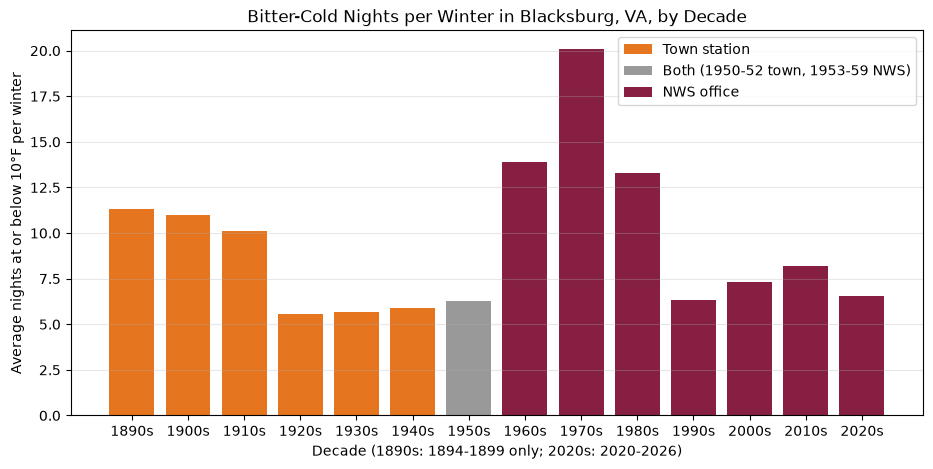

In [14]:
town_decades = by_decade.loc[1890:1940]
mixed_decade = by_decade.loc[1950:1950]
nws_decades = by_decade.loc[1960:2020]

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(town_decades['label'], town_decades['bitter_per_winter'], color='#E5751F', label='Town station')
ax.bar(mixed_decade['label'], mixed_decade['bitter_per_winter'], color='#999999', label='Both (1950-52 town, 1953-59 NWS)')
ax.bar(nws_decades['label'], nws_decades['bitter_per_winter'], color='#861F41', label='NWS office')

ax.set_title('Bitter-Cold Nights per Winter in Blacksburg, VA, by Decade')
ax.set_xlabel('Decade (1890s: 1894-1899 only; 2020s: 2020-2026)')
ax.set_ylabel('Average nights at or below 10°F per winter')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.show()

The decade chart separates the record into three regimes. The 1890s through 1910s averaged 10 to
11 bitter nights per winter. The 1920s through 1950s averaged about 6. The 1960s through 1980s rose
to between 13 and 20, and every decade since 1990 has averaged 6 to 8. Recent decades are therefore
well below the 1961-1990 level, close to the 1920s-1950s level, and below the early 1900s.

Two cautions. The 1890s and 2020s bars cover only six and seven winters, so they are less stable
than full decades. Decades that lost a winter to missing data (the 1920s, 1990s, and 2000s) are
averaged over nine winters; because the chart shows the average *per winter* rather than a total, a
missing winter does not shrink a bar by itself.

Averages also hide individual years. Ranking every winter by its bitter nights shows whether severe
winters have stopped occurring or have only become less frequent.

In [15]:
ranked_winters = complete_winters.sort_values('bitter_nights', ascending=False)
print('Ten winters with the most bitter nights:')
print(ranked_winters[['station', 'bitter_nights']].head(10))
print()
print('Bitter nights in the most recent winters:')
print(complete_winters.loc[2020:, 'bitter_nights'])

Ten winters with the most bitter nights:
       station  bitter_nights
winter                       
1978       nws             39
1977       nws             37
1918      town             30
1963       nws             27
1986       nws             25
1970       nws             23
1968       nws             23
1971       nws             22
1895      town             22
1900      town             22

Bitter nights in the most recent winters:
winter
2020     2
2021     2
2022     8
2023     3
2024     6
2025     9
2026    16
Name: bitter_nights, dtype: int64


Seven of the ten hardest winters fall between 1963 and 1986, and the two most severe (1977 and
1978, with 37 and 39 bitter nights) stand well apart from the rest. The other three come from the
early record: 1895, 1900, and 1918. No winter since 1986 makes the list; tenth place requires 22
bitter nights.

Severe winters have not disappeared. Winter 2026 recorded 16 bitter nights, essentially the
1961-1990 average. What was a typical winter a generation ago now ranks among the harder recent
ones.

## 8. Conclusion

**How have Blacksburg winters changed since 1893?** Not in a straight line. Winters warmed from the
1890s into a mild period in the 1920s through 1940s, turned sharply colder from the late 1950s
through the 1980s, and have been milder again since about 1990.

**How do recent winters compare with a generation ago?** They are milder. The last 30 winters
averaged about 2.5°F warmer than 1961-1990, and nights at or below 10°F fell from about 16 per winter
to 7. Ordinary freezing nights changed little (78 to 74). The change is concentrated in the severe
cold, not in whether winter is cold at all.

**Are recent winters unusual?** Not within the full record. The 1923-1952 period was milder than
today by every measure used here. Residents who say winters "aren't what they used to be" are
correct about the winters they remember, but those winters were the coldest stretch in Blacksburg's
130-year record, not its baseline.

### Limitations

- **Station change.** The record joins two stations about 5 km apart with no overlapping data. The
  checks in Section 6 found no abrupt shift, but a small offset of a degree or so cannot be ruled
  out. This affects the long-term comparison, not the generational one.
- **A single location.** Both stations represent one town. Changes around a station over decades,
  such as new buildings and pavement, can affect its readings, and this analysis did not research
  either station's history. A regional comparison would require additional stations.
- **Description, not explanation.** The analysis measures how winters changed. It does not identify
  causes, and the mid-century cold period in particular should not be interpreted without
  information from beyond this dataset.
- **Gaps and exclusions.** Winters 1893, 1924, 1995, and 2002 are missing or excluded, and snowfall
  was not analyzed because early records are incomplete.